In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
np.random.seed(42)

In [55]:
class SVM:
    def __init__(self,lr,n_iter,lambda_param):
        self.lr = lr
        self.n_iter = n_iter
        self.lambda_param = lambda_param
        self.w = None
        self.b = None
        
    def fit(self,x,y):
        self.x = x
        self.y = y
        self.m, self.n = x.shape
        # initialize parameters
        self.initialize_parameters()
        # SVM expects labels to be -1 and 1 (not 0 and 1)
        # This converts 0s to -1s if necessary
        self.y = np.where(self.y<=0,-1,1)
        # implement gradient decent algorithm for optimization
        for i in range(self.n_iter):
            self.update_weights()
            if i%100 ==0:
                loss = self.calculate_hinge_loss(self.x,self.y)
                print(f"Loss :{loss} ")
                
    def initialize_parameters(self):
        self.w = np.zeros(self.n)
        self.b = 0
        
    def update_weights(self):
        for idx,x_i in enumerate(self.x):
            # Check the Margin Condition: y_i * (w.x - b) >= 1
            condition = self.y[idx] * (np.dot(x_i,self.w)+self.b) >= 1
            if condition:
                dw = 2 * self.lambda_param * self.w
                db = 0
            else:
                dw = 2*self.lambda_param * self.w -(self.y[idx]*x_i) # (self.y[idx]*x_i)this results a vector. if we use np.dot it results scalar=>np.dot([],constant)= scalar
                db = -self.y[idx]
            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict(self,x):
        output = np.dot(x,self.w) + self.b
        # Return sign (-1 or 1), then map back to 0/1 for consistency
        pred_label = np.sign(output)
        pred = np.where(pred_label==1,1,0)
        return pred
        
    # hinge_loss
    def calculate_hinge_loss(self,x,y):
        """Calculates the total Hinge Loss + Regularization Term for the dataset (X, y)."""
        # L(w,b)= 1/2∥w∥^2  + λ∑max(0,1−yi(w⋅xi+b))
        # 1. Regularization Term
        regularizer = 0.5 * np.dot(self.w,self.w)
        y_ = np.where(y<=0,-1,1)
        # 2. hinge loss
        f_x = np.dot(x,self.w) + self.b
        hinge_loss = np.sum(np.maximum(0,1-y_*f_x))
        total_loss = regularizer + self.lambda_param *hinge_loss/x.shape[0]   # Divide by sample size (n) for average loss
        return total_loss

    #Error Rate (Classification Error/Accuracy)
    def calculate_accuracy(self,x,y):
        # Classification Error=Number of Misclassified Samples/Total Number of Samples
        pred = self.predict(x)
        y = np.where(y<=0,0,1)
        correct = np.sum(y == pred)
        accuracy = correct/ len(y)
        # Error Rate = 1 - Accuracy
        error_rate = 1-accuracy
        # return accuracy (%)
        return accuracy*100
    

In [22]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, n_features=2, centers=2, cluster_std=1.05, random_state=40)

In [23]:
X.shape,y.shape

((50, 2), (50,))

In [29]:
np.unique(y) # labels

array([0, 1])

In [52]:
model = SVM(lr=0.001,lambda_param=0.01,n_iter=1000)
model.fit(X,y)

Loss :0.021594568454301057 
Loss :0.17867974709935688 
Loss :0.19833026508010668 
Loss :0.1986129832509415 
Loss :0.1960257163465962 
Loss :0.1915394035708775 
Loss :0.19211858877332313 
Loss :0.1928361027180075 
Loss :0.19070920157147925 
Loss :0.1915433673919257 


During the first few iterations, the Gradient Descent algorithm finds that w=0 and b=0 is a terrible decision boundary. loss is low. It starts adjusting the weights (w) and bias (b) to properly separate the two classes.

In [45]:
print(f"Weights:{model.w}")
print(f"Bias:{model.b}")

Weights:[0.58977016 0.17946483]
Bias:0.1520000000000001


In [53]:
model.calculate_hinge_loss(X,y)

np.float64(0.1900182319100726)

In [54]:
model.calculate_accuracy(X,y)

np.float64(100.0)

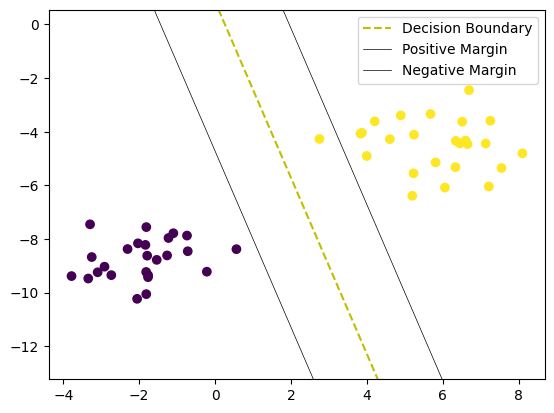

In [37]:
def visualize_svm():
    def get_hyperplane_value(x, w, b, offset):
        return (-w[0] * x + b + offset) / w[1]

    fig = plt.figure()
    ax = fig.add_subplot(1, 1, 1)
    
    # Plot data points
    plt.scatter(X[:, 0], X[:, 1], marker="o", c=y)

    x0_1 = np.amin(X[:, 0])
    x0_2 = np.amax(X[:, 0])

    # 1. Decision Boundary (w.x - b = 0)
    x1_1 = get_hyperplane_value(x0_1, model.w, model.b, 0)
    x1_2 = get_hyperplane_value(x0_2, model.w, model.b, 0)
    ax.plot([x0_1, x0_2], [x1_1, x1_2], "y--", label='Decision Boundary')

    # 2. Upper Margin (w.x - b = 1)
    x1_1_m = get_hyperplane_value(x0_1, model.w, model.b, 1)
    x1_2_m = get_hyperplane_value(x0_2, model.w, model.b, 1)
    ax.plot([x0_1, x0_2], [x1_1_m, x1_2_m], "k", linewidth=0.5, label='Positive Margin')

    # 3. Lower Margin (w.x - b = -1)
    x1_1_p = get_hyperplane_value(x0_1, model.w, model.b, -1)
    x1_2_p = get_hyperplane_value(x0_2, model.w, model.b, -1)
    ax.plot([x0_1, x0_2], [x1_1_p, x1_2_p], "k", linewidth=0.5, label='Negative Margin')

    x1_min = np.amin(X[:, 1])
    x1_max = np.amax(X[:, 1])
    ax.set_ylim([x1_min - 3, x1_max + 3])
    plt.legend()
    plt.show()

visualize_svm()

In [56]:
from sklearn.svm import SVC

In [57]:
model1 = SVC(kernel='linear',C=0.01)
model1.fit(X,y)

,C,0.01
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [60]:
model1.score(X,y)

1.0

In [64]:
model1.coef_

array([[0.23950155, 0.18821297]])